# Pair 3 — LightGCL vs XSimGCL

I compare two graph recommendation models on the **Amazon Reviews 2023  Musical Instruments** dataset. Both models use the same processed training graph and held-out test interactions. I focus on recommendation accuracy, catalogue coverage, training efficiency, and users whose recommendations differ.

**Selected runs:** LightGCL (DIM=64, one layer, SVD rank=5, contrastive weight=0.01, best epoch 62) and XSimGCL (DIM=128, two layers, contrastive weight=0.05, best epoch 12). These are locally adapted research implementations, not exact reproductions of the original experiments.

## 1. Setup

This notebook reads saved results; no model training or CUDA is required.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
rng = np.random.default_rng(SEED)
BASE = Path.cwd()
if not (BASE / "datasets" / "processed" / "train.csv").exists():
    BASE = BASE / "Models" / "Pair_03"
DATA = BASE / "datasets" / "processed"
OUT = BASE / "results" / "Comparison"
OUT.mkdir(parents=True, exist_ok=True)

# Change these if you saved the selected checkpoints in other result folders.
LIGHT = BASE / "results" / "LightGCL"
XSIM = BASE / "results" / "XSimGCL"

required = [DATA / "train.csv", DATA / "test.csv"]
for folder in (LIGHT, XSIM):
    required += [folder / "metrics.json", folder / "test_recommendations.csv", folder / "history.csv"]
missing = [str(f) for f in required if not f.exists()]
if missing:
    raise FileNotFoundError("Missing files. Set LIGHT/XSIM to your saved best runs:\n" + "\n".join(missing))

train = pd.read_csv(DATA / "train.csv")
test = pd.read_csv(DATA / "test.csv")
with open(DATA / "dataset_stats.json") as f:
    stats = json.load(f)
N_ITEMS = int(stats["num_items"])

def load_run(folder):
    with open(folder / "metrics.json") as f:
        metrics = json.load(f)
    rec = pd.read_csv(folder / "test_recommendations.csv")
    history = pd.read_csv(folder / "history.csv")
    return metrics, rec, history

lm, lr, lh = load_run(LIGHT)
xm, xr, xh = load_run(XSIM)
print("LightGCL:", LIGHT)
print("XSimGCL:", XSIM)
print("Evaluated users:", len(lr), len(xr))

LightGCL: c:\Users\royay\OneDrive\Desktop\COMP8410\Assignment 1\COMP8410_A1_49128299\Models\Pair_03\results\LightGCL
XSimGCL: c:\Users\royay\OneDrive\Desktop\COMP8410\Assignment 1\COMP8410_A1_49128299\Models\Pair_03\results\XSimGCL
Evaluated users: 7148 7148


## 2. Selected runs and overall results

I use each model's best checkpoint chosen on validation NDCG@20. The checks below flag an overwritten or mismatched run instead of silently comparing the wrong files.

In [2]:
# Check the expected selected configurations and outputs.
assert len(lr) == len(xr) == 7148, "Unexpected test-user count; check saved runs."
assert set(lr.user_idx) == set(xr.user_idx), "Models were evaluated on different test users."

checks = [("LightGCL", lm, 0.025038), ("XSimGCL", xm, 0.030151)]
for name, m, expected in checks:
    if abs(float(m["ndcg_at_20"]) - expected) > 0.001:
        raise ValueError(f"{name} NDCG@20 is {m['ndcg_at_20']:.4f}, not the selected result (~{expected:.4f}). Check the output folder.")

metrics = ["recall_at_10", "recall_at_20", "ndcg_at_10", "ndcg_at_20", "coverage_at_20"]
summary = pd.DataFrame({"LightGCL": lm, "XSimGCL": xm}).loc[metrics].astype(float)
summary.loc["best_val_ndcg_at_20"] = [float(lh.val_ndcg_at_20.max()), float(xh.val_ndcg_at_20.max())]
summary.loc["train_seconds"] = [float(lm["train_seconds"]), float(xm["train_seconds"])]
summary.loc["best_epoch"] = [float(lm["best_epoch"]), float(xm["best_epoch"])]
display(summary.round(4))
summary.to_csv(OUT / "metrics_comparison.csv")

,LightGCL,XSimGCL
recall_at_10,0.0368,0.0462
recall_at_20,0.0585,0.0667
ndcg_at_10,0.0195,0.0250
ndcg_at_20,0.0250,0.0302
coverage_at_20,0.7953,0.4171
best_val_ndcg_at_20,0.0315,0.0386
train_seconds,187.1706,30.6993
best_epoch,62.0000,12.0000


## 3. Accuracy, coverage and efficiency

Higher Recall and NDCG mean better ranking accuracy. Higher coverage means the model recommended more distinct items somewhere across all users; it does not measure within-list diversity.

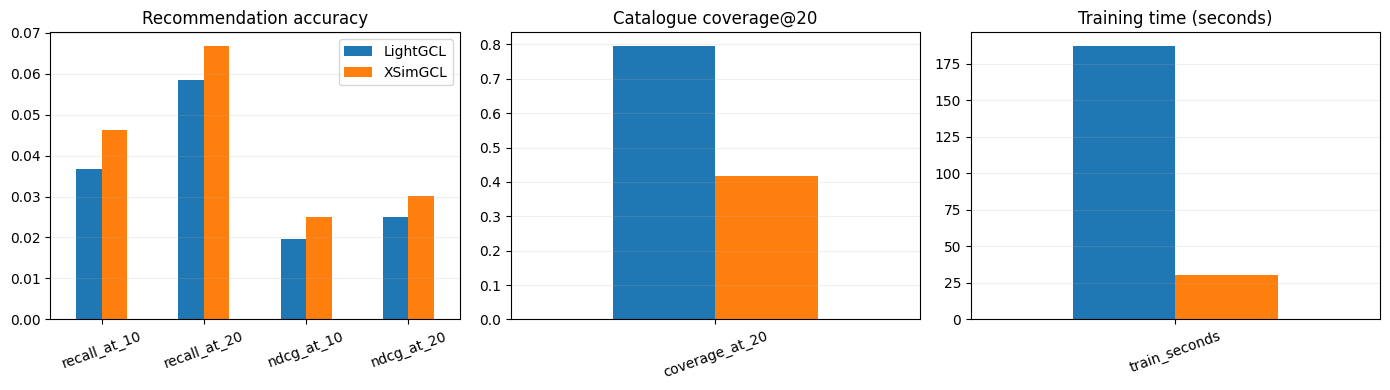

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, keys, title in [
    (axes[0], ["recall_at_10", "recall_at_20", "ndcg_at_10", "ndcg_at_20"], "Recommendation accuracy"),
    (axes[1], ["coverage_at_20"], "Catalogue coverage@20"),
    (axes[2], ["train_seconds"], "Training time (seconds)")
]:
    summary.loc[keys, ["LightGCL", "XSimGCL"]].plot(kind="bar", ax=ax, rot=20, legend=(ax is axes[0]))
    ax.set_title(title)
    ax.set_xlabel("")
    ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.savefig(OUT / "overall_metrics.png", dpi=160)
plt.show()

## 4. Training curves

The loss functions differ between models, so I compare their validation NDCG trends rather than interpreting absolute training losses as comparable.

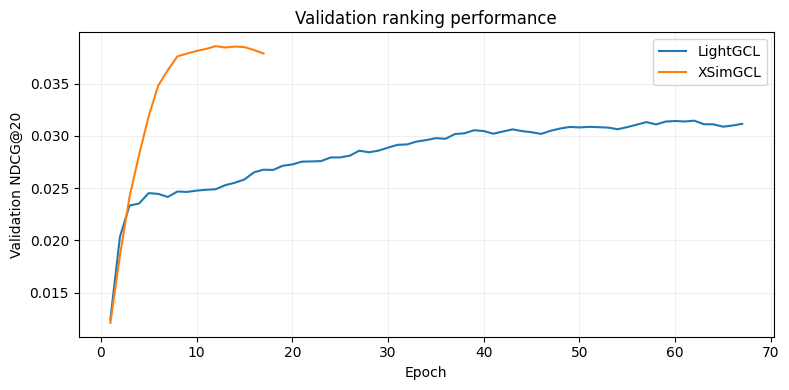

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(lh.epoch, lh.val_ndcg_at_20, label="LightGCL")
ax.plot(xh.epoch, xh.val_ndcg_at_20, label="XSimGCL")
ax.set(xlabel="Epoch", ylabel="Validation NDCG@20", title="Validation ranking performance")
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(OUT / "validation_comparison.png", dpi=160)
plt.show()

## 5. Popularity baseline

I recommend the most frequently interacted-with training items, excluding each user's seen training items. This gives a simple non-graph baseline under the same full-catalog evaluation setup.

In [5]:
counts = train.item_idx.value_counts()
popular = counts.index.to_numpy(dtype=int)
seen = train.groupby("user_idx")["item_idx"].apply(set).to_dict()
targets = test.groupby("user_idx")["item_idx"].apply(set).to_dict()

def score_top20(ranked, truth):
    row = {}
    for k in (10, 20):
        hits = np.array([int(int(i) in truth) for i in ranked[:k]])
        row[f"recall_at_{k}"] = float(hits.sum() / len(truth))
        dcg = float((hits / np.log2(np.arange(2, k + 2))).sum())
        ideal = float((1 / np.log2(np.arange(2, min(k, len(truth)) + 2))).sum())
        row[f"ndcg_at_{k}"] = dcg / ideal if ideal else 0.0
    return row

rows = []
recommended = set()
for user, truth in targets.items():
    top = [int(i) for i in popular if int(i) not in seen[user]][:20]
    recommended.update(top)
    rows.append({"user_idx": user, **score_top20(top, truth),
                 "target_items": " ".join(map(str, sorted(truth))),
                 "top20_items": " ".join(map(str, top))})
pop = pd.DataFrame(rows)
pop_metrics = {col: pop[col].mean() for col in metrics if col != "coverage_at_20"}
pop_metrics["coverage_at_20"] = len(recommended) / N_ITEMS
print("Popularity baseline:")
display(pd.Series(pop_metrics).round(4))
pop.to_csv(OUT / "popularity_test_recommendations.csv", index=False)

baseline = pd.DataFrame({"Popularity": pop_metrics, "LightGCL": lm, "XSimGCL": xm}).loc[metrics].astype(float)
display(baseline.round(4))
baseline.to_csv(OUT / "baseline_comparison.csv")

Popularity baseline:


recall_at_10      0.0315
recall_at_20      0.0485
ndcg_at_10        0.0172
ndcg_at_20        0.0214
coverage_at_20    0.0016
dtype: float64

,Popularity,LightGCL,XSimGCL
recall_at_10,0.0315,0.0368,0.0462
recall_at_20,0.0485,0.0585,0.0667
ndcg_at_10,0.0172,0.0195,0.0250
ndcg_at_20,0.0214,0.0250,0.0302
coverage_at_20,0.0016,0.7953,0.4171


## 6. Paired user-level analysis

Both models recommend to the same 7,148 test users. I compare each user's outcome and bootstrap the paired difference (XSimGCL − LightGCL). Confidence intervals indicate uncertainty for this sample, not proof of generalisation to all Amazon customers.

In [6]:
a = lr.set_index("user_idx").sort_index()
b = xr.set_index("user_idx").sort_index()
assert a.index.equals(b.index)

n_boot = 2000
results = []
for metric in ["recall_at_10", "recall_at_20", "ndcg_at_10", "ndcg_at_20"]:
    delta = (b[metric] - a[metric]).to_numpy(dtype=float)
    sample_means = np.empty(n_boot)
    for j in range(n_boot):
        sample_means[j] = delta[rng.integers(0, len(delta), len(delta))].mean()
    low, high = np.quantile(sample_means, [0.025, 0.975])
    results.append({"metric": metric, "XSim_minus_Light": delta.mean(),
                    "CI_95_low": low, "CI_95_high": high,
                    "XSim_better_users": int((delta > 0).sum()),
                    "Light_better_users": int((delta < 0).sum()),
                    "ties": int((delta == 0).sum())})
paired = pd.DataFrame(results).set_index("metric")
display(paired.round(5))
paired.to_csv(OUT / "paired_bootstrap.csv")

,XSim_minus_Light,CI_95_low,CI_95_high,XSim_better_users,Light_better_users,ties
metric,,,,,,
recall_at_10,0.00937,0.00532,0.01357,141,74,6933
recall_at_20,0.00825,0.00364,0.01287,175,116,6857
ndcg_at_10,0.00541,0.00320,0.00784,233,134,6781
ndcg_at_20,0.00511,0.00298,0.00724,344,211,6593


## 7. Where do the models differ?

I inspect a few users where one model found the held-out product and the other missed it. Item IDs are mapped back to Amazon product identifiers (`parent_asin`) when the mapping is available. These are examples of held-out-item retrieval, not a judgement of product quality.

In [7]:
examples = pd.DataFrame({
    "Light_recall20": a["recall_at_20"],
    "XSim_recall20": b["recall_at_20"],
    "Light_ndcg20": a["ndcg_at_20"],
    "XSim_ndcg20": b["ndcg_at_20"],
    "target_items": a["target_items"],
    "Light_top20": a["top20_items"],
    "XSim_top20": b["top20_items"]
})
examples["XSim_minus_Light"] = examples.XSim_ndcg20 - examples.Light_ndcg20
item_map_file = DATA / "item_mapping.csv"
if item_map_file.exists():
    item_map = pd.read_csv(item_map_file).set_index("item_idx")["parent_asin"].to_dict()
    def to_asins(value):
        return ", ".join(str(item_map.get(int(v), v)) for v in str(value).split()[:5])
    examples["target_asin"] = examples.target_items.map(to_asins)
    examples["Light_top5_asin"] = examples.Light_top20.map(to_asins)
    examples["XSim_top5_asin"] = examples.XSim_top20.map(to_asins)

cols = ["Light_ndcg20", "XSim_ndcg20", "XSim_minus_Light"]
cols += [x for x in ["target_asin", "Light_top5_asin", "XSim_top5_asin"] if x in examples]
print("XSimGCL does better on these users:")
display(examples.sort_values("XSim_minus_Light", ascending=False)[cols].head(5))
print("LightGCL does better on these users:")
display(examples.sort_values("XSim_minus_Light")[cols].head(5))
examples.to_csv(OUT / "user_level_comparison.csv")

XSimGCL does better on these users:


,Light_ndcg20,XSim_ndcg20,XSim_minus_Light,target_asin,Light_top5_asin,XSim_top5_asin
user_idx,,,,,,
549,0.0,1.0,1.0,B0BCK6L7S5,"B0BXT385LV, B0BPLFP5P6, B07WJYTDMH, B00T3ZRI44...","B0BCK6L7S5, B012VQ5A7S, B07L5B64RG, B0BPLFP5P6..."
7369,0.0,1.0,1.0,B004XNK7AI,"B07L8ZZFF5, B01K1EJQ9U, B01N41SI41, B0002F4UG8...","B004XNK7AI, B00H4PEMM6, B07B4ZZVDV, B005J3EZZY..."
9069,0.0,1.0,1.0,B0BKZ6M28F,"B076BWPKRL, B0BN6HN5B8, B0002F71PK, B09HCVLH2K...","B0BKZ6M28F, B00GXNZP80, B0B2TND26L, B0C3LKLKLR..."
3138,0.0,1.0,1.0,B0C6H9T5T6,"B005A4U060, B06XKTM5W6, B0BJ8WDC13, B08DZ2B791...","B0C6H9T5T6, B016QUXTZU, B09MSQBZFJ, B00DY1F2CS..."
5516,0.0,1.0,1.0,B0C67HCGBR,"B015IJIO5U, B09857JRP2, B00NPAMDQ6, B0B8M5FJ9W...","B0C67HCGBR, B091MZPYBQ, B0B95V41NR, B016QUXTZU..."


LightGCL does better on these users:


,Light_ndcg20,XSim_ndcg20,XSim_minus_Light,target_asin,Light_top5_asin,XSim_top5_asin
user_idx,,,,,,
5529,1.0,0.0,-1.0,B075R91PXY,"B075R91PXY, B00OYUSHJS, B0B31RCL2G, B00LOAASPC...","B0C67HCGBR, B00OYUSHJS, B07N5J3GTB, B099NYHNRG..."
3603,1.0,0.0,-1.0,B07SFYY1VJ,"B07SFYY1VJ, B0BKZ61YJJ, B07R21522F, B00DY1F2CS...","B0BKZ61YJJ, B0BKZ6M28F, B0B2TND26L, B0731S4FHV..."
7410,1.0,0.0,-1.0,B00IFOTSJW,"B00IFOTSJW, B0BKZ3GCGR, B0BSGM6CQ9, B018FCZKR2...","B08R5GM6YB, B004XNK7AI, B07GFH8NTB, B0BTC9YJ2W..."
1693,1.0,0.0,-1.0,B09857JRP2,"B09857JRP2, B015IJIO5U, B0B8M5FJ9W, B0BTC9YJ2W...","B00H35YIJE, B0BSGM6CQ9, B09RTZ26KV, B0BPLFP5P6..."
1031,1.0,0.0,-1.0,B07BQVJY7W,"B07BQVJY7W, B09G5QS1VD, B07CBT4SYD, B0BQ64RG5V...","B0BKR2ZM9X, B0BCK6L7S5, B0BPJ4Q6FJ, B0B95V41NR..."


## 8. User-history analysis

I group users by the number of positive training interactions to see whether either model has particular difficulty with shorter histories. These are descriptive results; the groups may not be equally sized.

,users,LightGCL_NDCG20,XSimGCL_NDCG20
history_group,,,
1–3,2757,0.0254,0.0307
4–7,2870,0.0259,0.0308
8+,1521,0.0227,0.0278


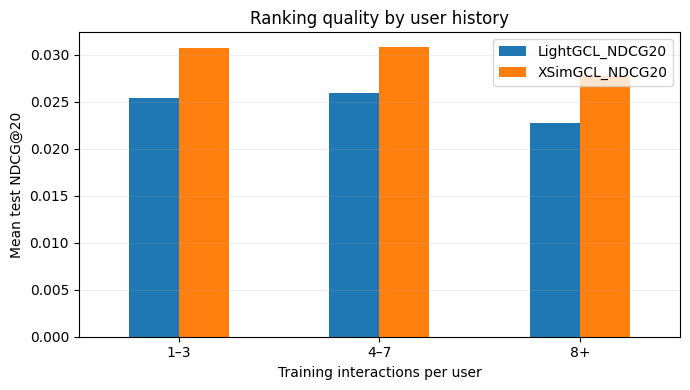

In [8]:
history_size = train.groupby("user_idx").size()
activity = examples.join(history_size.rename("train_interactions"), how="left")
activity["history_group"] = pd.cut(activity.train_interactions, bins=[0, 3, 7, float("inf")], labels=["1–3", "4–7", "8+"])
by_history = activity.groupby("history_group", observed=True).agg(
    users=("Light_ndcg20", "size"),
    LightGCL_NDCG20=("Light_ndcg20", "mean"),
    XSimGCL_NDCG20=("XSim_ndcg20", "mean")
)
display(by_history.round(4))
by_history.to_csv(OUT / "history_group_comparison.csv")
ax = by_history[["LightGCL_NDCG20", "XSimGCL_NDCG20"]].plot(kind="bar", figsize=(7, 4), rot=0)
ax.set(xlabel="Training interactions per user", ylabel="Mean test NDCG@20", title="Ranking quality by user history")
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.savefig(OUT / "user_history_comparison.png", dpi=160)
plt.show()

## 9. Discussion

### Recommendation Performance

XSimGCL achieved better recommendation accuracy than LightGCL across all four ranking metrics. Its test NDCG@20 was 0.0302 compared with LightGCL's 0.0250, while Recall@20 was 0.0667 compared with 0.0585. Both models also outperformed the popularity baseline, indicating that graph-based learning provided some improvement over recommending popular products.

The paired bootstrap results support XSimGCL's advantage, as the 95% confidence intervals for the differences in Recall and NDCG were all above zero. However, both models still had relatively low recommendation accuracy, and most users did not have their held-out product retrieved within the top 20.

### Catalogue Coverage

LightGCL achieved much higher catalogue coverage (79.53%) than XSimGCL (41.71%). This suggests that LightGCL recommended a wider range of products, while XSimGCL concentrated its recommendations on a smaller portion of the catalogue.

For Amazon, this presents a trade-off. XSimGCL may be more effective at ranking relevant products, while LightGCL could help expose a broader selection of musical instruments and accessories. However, higher coverage does not necessarily mean greater recommendation diversity or customer satisfaction.

### User-Level Analysis

XSimGCL performed better across all three user-history groups. Interestingly, both models achieved slightly lower NDCG@20 for users with eight or more training interactions. This suggests that having more interaction history does not necessarily guarantee better recommendations.

The individual recommendation examples also show that neither model consistently outperforms the other for every user. Some held-out products were ranked first by XSimGCL but missed by LightGCL, while other examples showed the opposite.

### Efficiency and Limitations

XSimGCL required less training time in the recorded experiments, although training efficiency depends on the model configuration and hardware conditions.

The evaluation used a 10,000-user subset of Amazon Musical Instruments with positive interactions defined by ratings of at least four stars. Products absent from the training catalogue were excluded from evaluation, meaning the results only measure recommendations for known products.

Both implementations were adapted from their published architectures, and the experiments used a single random seed. Further testing across different datasets and seeds would help determine whether the observed differences are consistent.

### Recommendation

Based on these results, I would recommend XSimGCL as the stronger candidate for Amazon when ranking accuracy is the main priority. It achieved higher Recall and NDCG scores and performed better across different user-history groups.

However, LightGCL's higher catalogue coverage makes it worth considering when broader product exposure is important. Neither model should be deployed without further evaluation, particularly because their overall recommendation accuracy remains relatively low.

## 10. Reproducibility

The dataset uses the official Musical Instruments train/validation/test splits, filtered to ratings ≥4 and 10,000 sampled users (seed 42). User and product mappings were created from training data only. Validation selected checkpoints and hyperparameters; the same held-out test users and full training catalogue were used for evaluation, masking previously seen training items. See `dataset_preprocessing.py`, `LightGCL.ipynb`, and `XSimGCL.ipynb` for implementation and training details.
